In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv("palmerpenguins_original.csv")

In [3]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 344
Number of Columns: 8


In [4]:
print("\nFirst Five Rows:")
display(df.head())


First Five Rows:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [5]:
print("\nLast Five Rows:")
display(df.tail())


Last Five Rows:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009
343,Chinstrap,Dream,50.2,18.7,198.0,3775.0,female,2009


In [6]:
print("\n Shape:", df.shape)


 Shape: (344, 8)


In [7]:
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), object(3)
memory usage: 21.6+ KB


In [8]:
# Display numerical and categorical columns
numerical_columns = df.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("\nNumerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)


Numerical Columns:
['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'year']

Categorical Columns:
['species', 'island', 'sex']


In [9]:
print("Numerical Summary Statistics:")
display(df[numerical_columns].describe())

Numerical Summary Statistics:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.000000,342.000000,342.000000,342.000000,344.000000
mean,43.921930,17.151170,200.915205,4201.754386,2008.029070
std,5.459584,1.974793,14.061714,801.954536,0.818356
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


In [10]:
print("\nCategorical Summary Statistics:")
display(df[categorical_columns].describe())


Categorical Summary Statistics:


,species,island,sex
count,344,344,333
unique,3,3,2
top,Adelie,Biscoe,male
freq,152,168,168


In [11]:
print("\nPotential Target Column: species")
print(
    "Reason: Species is a categorical variable "
    "that could be predicted from penguin measurements "
    "in a future classification task."
)


Potential Target Column: species
Reason: Species is a categorical variable that could be predicted from penguin measurements in a future classification task.


In [12]:
# Count missing values in each column
missing_count = df.isnull().sum()

# Calculate percentage of missing values
missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

# Create a missing-value summary
missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage (%)": missing_percentage.round(2)
})

print("Missing Value Summary:")

display(missing_summary)

Missing Value Summary:


,Missing Values,Missing Percentage (%)
species,0,0.00
island,0,0.00
bill_length_mm,2,0.58
bill_depth_mm,2,0.58
flipper_length_mm,2,0.58
body_mass_g,2,0.58
sex,11,3.20
year,0,0.00


In [13]:
# Create a copy of the original dataset
df_clean = df.copy()

print("Original Dataset Shape:", df.shape)
print("Copied Dataset Shape:", df_clean.shape)

Original Dataset Shape: (344, 8)
Copied Dataset Shape: (344, 8)


In [14]:
# Identify numerical measurement columns
measurement_columns = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

In [15]:
# Fill missing numerical measurements using the median
for column in measurement_columns:
    median_value = df_clean[column].median()

    df_clean[column] = df_clean[column].fillna(
        median_value
    )

In [16]:
# Fill missing categorical values using the mode
sex_mode = df_clean["sex"].mode()[0]

df_clean["sex"] = df_clean["sex"].fillna(sex_mode)

In [17]:
print("\nMissing values after handling:")

display(df_clean.isnull().sum())

print(
    "\nTotal remaining missing values:",
    df_clean.isnull().sum().sum()
)


Missing values after handling:


species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
year                 0
dtype: int64


Total remaining missing values: 0


In [18]:
# Check duplicate rows before removing any
duplicate_count = df_clean.duplicated().sum()

print("Duplicate Rows Found:", duplicate_count)

Duplicate Rows Found: 0


In [19]:
# Display duplicate records if present
if duplicate_count > 0:
    print("\nDuplicate Records:")
    display(df_clean[df_clean.duplicated(keep=False)])
else:
    print("No duplicate rows found.")


No duplicate rows found.


In [20]:
# Remove unnecessary leading and trailing spaces
categorical_columns_clean = [
    "species",
    "island",
    "sex"
]

for column in categorical_columns_clean:
    df_clean[column] = df_clean[column].str.strip()

In [21]:
# Display unique category values
print("\nUnique Species:")
print(df_clean["species"].unique())

print("\nUnique Islands:")
print(df_clean["island"].unique())

print("\nUnique Sex Categories:")
print(df_clean["sex"].unique())

# Verify duplicates after cleaning
print(
    "\nRemaining Duplicate Rows:",
    df_clean.duplicated().sum()
)


Unique Species:
['Adelie' 'Gentoo' 'Chinstrap']

Unique Islands:
['Torgersen' 'Biscoe' 'Dream']

Unique Sex Categories:
['male' 'female']

Remaining Duplicate Rows: 0


In [22]:
# Summary statistics after cleaning
print("Summary Statistics After Cleaning:")
display(df_clean[measurement_columns + ["year"]].describe())

Summary Statistics After Cleaning:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,344.000000,344.000000,344.000000,344.000000,344.000000
mean,43.925000,17.152035,200.892442,4200.872093,2008.029070
std,5.443792,1.969060,14.023826,799.696532,0.818356
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.275000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


In [24]:
# Frequency counts for categorical columns
print("\nSpecies Frequency:")
display(df_clean["species"].value_counts())


Species Frequency:


species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

In [25]:
print("\nIsland Frequency:")
display(df_clean["island"].value_counts())


Island Frequency:


island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64

In [26]:
print("\nSex Frequency:")
display(df_clean["sex"].value_counts())


Sex Frequency:


sex
male      179
female    165
Name: count, dtype: int64

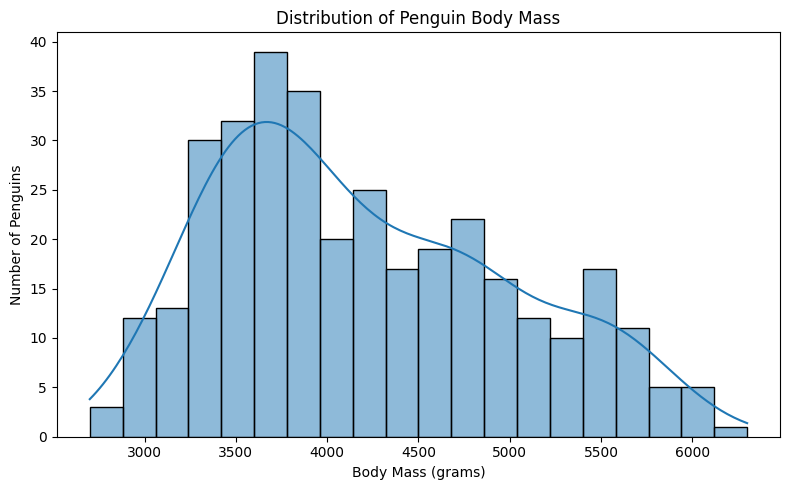

In [27]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x="body_mass_g",
    bins=20,
    kde=True
)

plt.title("Distribution of Penguin Body Mass")
plt.xlabel("Body Mass (grams)")
plt.ylabel("Number of Penguins")

plt.tight_layout()
plt.show()

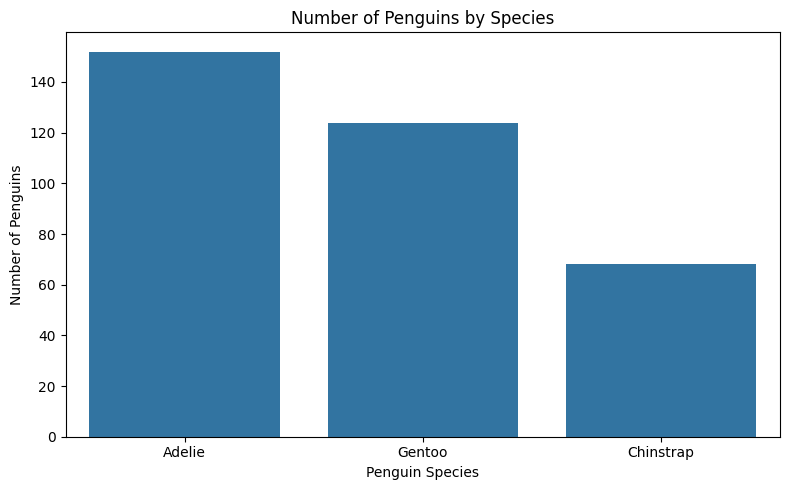

In [28]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="species",
    order=df_clean["species"].value_counts().index
)

plt.title("Number of Penguins by Species")
plt.xlabel("Penguin Species")
plt.ylabel("Number of Penguins")

plt.tight_layout()
plt.show()

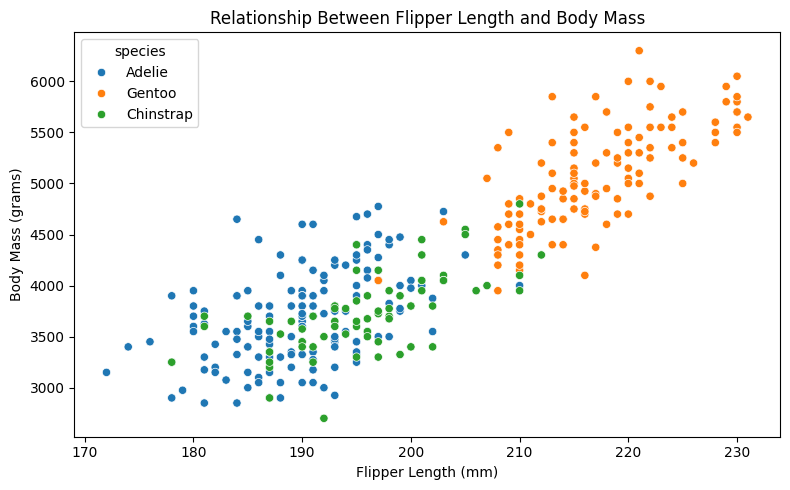

In [29]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean,
    x="flipper_length_mm",
    y="body_mass_g",
    hue="species"
)

plt.title("Relationship Between Flipper Length and Body Mass")
plt.xlabel("Flipper Length (mm)")
plt.ylabel("Body Mass (grams)")

plt.tight_layout()
plt.show()

In [31]:
# Create a copy before encoding
df_encoded = df_clean.copy()

In [32]:
# Identify categorical input features
categorical_features = [
    "island",
    "sex"
]

print("Categorical Features Before Encoding:")
display(df_encoded[categorical_features].head())

Categorical Features Before Encoding:


,island,sex
0,Torgersen,male
1,Torgersen,female
2,Torgersen,female
3,Torgersen,male
4,Torgersen,female


In [33]:
# Apply one-hot encoding
df_encoded = pd.get_dummies(
    df_encoded,
    columns=categorical_features,
    dtype=int
)

In [34]:
print("\nDataset After One-Hot Encoding:")
display(df_encoded.head())


Dataset After One-Hot Encoding:


,species,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year,island_Biscoe,island_Dream,island_Torgersen,sex_female,sex_male
0,Adelie,39.10,18.7,181.0,3750.0,2007,0,0,1,0,1
1,Adelie,39.50,17.4,186.0,3800.0,2007,0,0,1,1,0
2,Adelie,40.30,18.0,195.0,3250.0,2007,0,0,1,1,0
3,Adelie,44.45,17.3,197.0,4050.0,2007,0,0,1,0,1
4,Adelie,36.70,19.3,193.0,3450.0,2007,0,0,1,1,0


In [35]:
print("\nColumns After Encoding:")
print(df_encoded.columns.tolist())


Columns After Encoding:
['species', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'year', 'island_Biscoe', 'island_Dream', 'island_Torgersen', 'sex_female', 'sex_male']


In [36]:
print("\nDataset Shape After Encoding:")
print(df_encoded.shape)


Dataset Shape After Encoding:
(344, 11)


Scaling

In [38]:
# Create a copy before scaling
df_prepared = df_encoded.copy()

# Numerical measurement features to scale
scaling_columns = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

In [39]:
# Display values before scaling
print("Before Scaling:")
display(df_prepared[scaling_columns].head())

Before Scaling:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,39.10,18.7,181.0,3750.0
1,39.50,17.4,186.0,3800.0
2,40.30,18.0,195.0,3250.0
3,44.45,17.3,197.0,4050.0
4,36.70,19.3,193.0,3450.0


In [40]:
# Initialize the scaler
scaler = StandardScaler()

# Apply standardization
df_prepared[scaling_columns] = scaler.fit_transform(
    df_prepared[scaling_columns]
)

In [41]:
# Display values after scaling
print("\nAfter Standard Scaling:")
display(df_prepared[scaling_columns].head())


After Standard Scaling:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,-0.887622,0.787289,-1.420541,-0.564625
1,-0.814037,0.126114,-1.063485,-0.502010
2,-0.666866,0.431272,-0.420786,-1.190773
3,0.096581,0.075255,-0.277964,-0.188936
4,-1.329133,1.092447,-0.563608,-0.940314


In [42]:
# Verify approximate means and standard deviations
print("\nMeans After Scaling:")
display(df_prepared[scaling_columns].mean().round(4))

print("\nStandard Deviations After Scaling:")
display(df_prepared[scaling_columns].std().round(4))


Means After Scaling:


bill_length_mm      -0.0
bill_depth_mm        0.0
flipper_length_mm    0.0
body_mass_g          0.0
dtype: float64


Standard Deviations After Scaling:


bill_length_mm       1.0015
bill_depth_mm        1.0015
flipper_length_mm    1.0015
body_mass_g          1.0015
dtype: float64

In [43]:
# Verify the final prepared dataset

print("Final Prepared Dataset Shape:")
print(df_prepared.shape)

print("\nRemaining Missing Values:")
print(df_prepared.isnull().sum())

print(
    "\nTotal Missing Values:",
    df_prepared.isnull().sum().sum()
)

print(
    "\nRemaining Duplicate Rows:",
    df_prepared.duplicated().sum()
)

print("\nFinal Column Names:")
print(df_prepared.columns.tolist())

# Display a sample of the prepared dataset
print("\nFirst Five Rows of the Prepared Dataset:")
display(df_prepared.head())

Final Prepared Dataset Shape:
(344, 11)

Remaining Missing Values:
species              0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
year                 0
island_Biscoe        0
island_Dream         0
island_Torgersen     0
sex_female           0
sex_male             0
dtype: int64

Total Missing Values: 0

Remaining Duplicate Rows: 0

Final Column Names:
['species', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'year', 'island_Biscoe', 'island_Dream', 'island_Torgersen', 'sex_female', 'sex_male']

First Five Rows of the Prepared Dataset:


,species,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year,island_Biscoe,island_Dream,island_Torgersen,sex_female,sex_male
0,Adelie,-0.887622,0.787289,-1.420541,-0.564625,2007,0,0,1,0,1
1,Adelie,-0.814037,0.126114,-1.063485,-0.502010,2007,0,0,1,1,0
2,Adelie,-0.666866,0.431272,-0.420786,-1.190773,2007,0,0,1,1,0
3,Adelie,0.096581,0.075255,-0.277964,-0.188936,2007,0,0,1,0,1
4,Adelie,-1.329133,1.092447,-0.563608,-0.940314,2007,0,0,1,1,0


In [44]:
# Save the prepared dataset separately
output_file = "prepared_penguins.csv"

df_prepared.to_csv(
    output_file,
    index=False
)

print("\nPrepared dataset saved successfully.")
print("File Name:", output_file)


Prepared dataset saved successfully.
File Name: prepared_penguins.csv
